# Customer Segmentation with Clustering

The work outlined here has been originally submitted as a project for the CAM PACE DS P1 26 Programme.


## **Business Context**
An e-commerce data set from a real-world organisation has been provided to perform customer segmentation with clustering models to improve marketing efforts (SAS, 2024). It is a transnational data set with customers from five continents (Oceania, North America, Europe, Africa, and Asia) and 47 countries.

The data set contains 951,668 rows, each representing a product a customer ordered. The data set contains details about the customer (e.g. location, product type, loyalty member) and order (e.g. days to delivery, delivery date, order date, cost, quantity ordered, profit) based on orders between 1 January 2012 and 30 December 2016.

As each customer is unique, it is critical to identify and/or create new features for customer segmentation to inform marketing efforts. The data set has 20 features
- **Quantity:** The quantity the customer orders (e.g. 1, 2, 3).
- **City:** Name of the customer's residence (e.g. Leinster, Berowra, Northbridge).
- **Continent:** Name of the continent where the customer resides (Oceania, North America).
- **Postal code:** Where the customer resides (e.g. 6437, 2081, 2063).   
State province: State or province where the customer resides (e.g. Western Australia, Quebec, New South Wales).
- **Order date:** The date the order was placed (e.g. 1 January 2012, 20 June 2014).
- **Delivery date:** The date the order was delivered (e.g. 12 April 2014, 19 November 2016).
- **Total revenue:** Total revenue based on ordered items in USD (e.g. 123.80, 85.10).
- **Unit cost:** Cost per unit ordered in USD (e.g. 9.10, 56.90).
- **Discount:** Percentage or normal total retail price (e.g. 50%, 30%).
- **Order type label:** Method in which the order was placed (e.g. internet sale, retail sale).
- **Customer country label:** The country where the customer resides (e.g. Australia, Canada, Switzerland).
- **Customer birthdate:** The date the customer was born (e.g. 8 May 1978, 18 December 1987).
- **Customer group:** Loyalty member group (e.g. internet/catalogue customers, Orion club gold members).
- **Customer type:** Loyalty member level (e.g. internet/catalogue customers, Orion club gold members high activity).
- **Order ID:** Unique order identifier (e.g. 1230000033).
- **Profit:** Total profit is calculated: $Total\:profit=Total\:revenue-(Unit\:cost\times Quantity)$.
- **Days to delivery:** The number of days for delivery is calculated: $Delivery\:days=Delivery\:date-Order\:date$ (e.g. 6, 3, 2).
- **Loyalty number:** Loyal customer (99) versus non-loyal customer (0).
- **Customer ID:** A unique identifier for the customer (e.g. 8818, 47793).

Since we have a transnational data set, which implies customers from different continents, several metrics are important when performing customer segmentation for target marketing.

From a marketing perspective, the following five metrics help to understand the nuance of the customer base, buying behaviour, preferences, and value to the business.
- **Frequency** indicates how often a customer purchases over a given period of time. A high frequency indicates a loyal customer, a high level of satisfaction, trust or brand loyalty, and/or effective marketing efforts. Frequency based on purchases guides a business in the effectiveness of target marketing campaigns and how to target less active customers.
- **Recency** measures how recently a customer made a purchase or placed an order. It helps predict customer churn (turnover) and engagement. A customer is a business’s most valuable asset, so securing customer retention is essential. As a result, recent customer activity can indicate their overall satisfaction and engagement.
- **Customer lifetime value (CLV)** indicates the average or total value a customer contributes to a business over the course of their relationship. In other words, CLV is a metric of the total income a business can expect to generate from a customer as long as said customer remains a loyal client. CLV helps to prioritise marketing efforts and resources as it focuses on customers who are expected to bring the most value over time. Therefore, retaining high-value customers.
- The **average unit cost** indicates if the customer prefers low cost or high cost items. This is related to the profitability of purchases. Customers buying products with a higher average unit cost price should be targeted differently. Customer segmentation assists in identifying these customers.
- **Customer age** indicates the number of years a customer has lived.

We are asked to use these five features as an input for your clustering model.

Expect the following data science challenges when performing customer segmentation:
1. **Data quality and management:** Data tends to be prone to inaccuracy, inconsistency, and incompleteness. The customer segments should be clearly defined, easily understood, and simple to incorporate into current and future strategies. Special attention should be paid to feature engineering and data preprocessing.
2. **Relevance segmentation:** The most relevant criteria (features) should be used for customer segmentation. Choosing the wrong or irrelevant criteria might dilute the clustering. As a result, cluster characteristics might overlap.
3. **Dynamic customer behaviour:** Customer preferences and behaviour can be seasonal, change rapidly based on new trends, or be influenced by personal and economic factors.  
4. **Privacy and ethical concerns:** Businesses must navigate the ethical and legal implications when collecting and analysing customer data. Data scientists must be unbiased regarding gender, race, country, etc.
5. **Actionability:** Creating segments that are too broad might ignore subtle but essential differences between customers, while segments that are too narrow might not be actionable. Creating a balance is important for marketing efficiency.

How we approach these challenges underscores the importance of understanding the business scenario for effective customer segmentation. Without direct input from the marketing team or domain experts, customer segmentation must be approached with a keen awareness of the nuanced relationships between different features and their potential implications for operational integrity.


<br></br>

> **Disclaimer**
>
> Note that although a real-life data set was provided, the business context in this project is fictitious. Any resemblance to companies and persons (living or dead) is coincidental.





## 1.Data Pre-Processing


### 1.1 Import the required libraries and load the dataset

In [ ]:
# Import the necessary libraries.
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib as mpl
from google.colab import files
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_samples, silhouette_score
from scipy.spatial.distance import pdist, squareform
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE



In [ ]:
df = pd.read_csv('https://github.com/FourthRevGitHub/CAM_DS_Public-Data-Sets/raw/main/Course%201/Week%206/CUSTOMERS_CLEAN.zip')

### 1.2 Initial look at the dataset

In [ ]:
print(df.shape)
df.head()


(951669, 20)


,Quantity,City,Continent,Postal_Code,State_Province,Order_Date,Delivery_Date,Total Revenue,Unit Cost,Discount,OrderTypeLabel,CustomerCountryLabel,Customer_BirthDate,Customer_Group,Customer_Type,Order ID,Profit,Days to Delivery,Loyalty Num,Customer ID
0,3,Leinster,Oceania,6437,Western Australia,01JAN2012,07JAN2012,$28.50,$9.10,.,Internet Sale,Australia,08MAY1978,Internet/Catalog Customers,Internet/Catalog Customers,1230000033,$1.20,6,99,8818
1,2,Berowra,Oceania,2081,New South Wales,01JAN2012,04JAN2012,$113.40,$56.90,.,Internet Sale,Australia,13DEC1978,Orion Club Gold members,Orion Club Gold members high activity,1230000204,($0.40),3,99,47793
2,2,Berowra,Oceania,2081,New South Wales,01JAN2012,04JAN2012,$41.00,$18.50,.,Internet Sale,Australia,13DEC1978,Orion Club Gold members,Orion Club Gold members high activity,1230000204,$4.00,3,99,47793
3,1,Northbridge,Oceania,2063,New South Wales,01JAN2012,03JAN2012,$35.20,$29.60,.,Internet Sale,Australia,22JUN1997,Orion Club Gold members,Orion Club Gold members high activity,1230000268,$5.60,2,0,71727
4,1,Montréal,North America,NaN,Quebec,01JAN2012,04JAN2012,$24.70,$23.60,.,Internet Sale,Canada,28JAN1978,Orion Club Gold members,Orion Club Gold members medium activity,1230000487,$1.10,3,99,74503


In [ ]:
num_cols=df.select_dtypes(include='number').columns.tolist()
cat_cols=df.select_dtypes(include='object').columns.tolist()

print('Numerical Columns:', num_cols)
print('Categorical Columns:', cat_cols)
print(len(cat_cols))


Numerical Columns: ['Quantity', 'Order ID', 'Days to Delivery', 'Loyalty Num', 'Customer ID']
Categorical Columns: ['City', 'Continent', 'Postal_Code', 'State_Province', 'Order_Date', 'Delivery_Date', 'Total Revenue', 'Unit Cost', 'Discount', 'OrderTypeLabel', 'CustomerCountryLabel', 'Customer_BirthDate', 'Customer_Group', 'Customer_Type', 'Profit']
15


The dataset has 20 features of which 5 contains numerical data and 15 contains categorical data. Amongst the categorical features, we see 'Total Revenue', 'Unit Cost' and 'Profit' which can easily be converted to numerical columns if needed. Also worth noting is that for columns 'Order_Date', 'Delivery_Date' and 'Customer_BirthDate' the  date is not recorded in a standard format. Furthermore, there are rows with NaN values.

### 1.3 Check for missing values

In [ ]:
df.isnull().sum()

,0
Quantity,0
City,135
Continent,0
Postal_Code,3716
State_Province,117192
Order_Date,0
Delivery_Date,0
Total Revenue,0
Unit Cost,0
Discount,0


The 'State_Province', 'Postal_Code' and 'City' features which all relate to geographic location present with a significant percentage of missing values. As the segmentation analysis will not involve these features, it is acceptable to skip data imputation to prevent potential loss of information.

### 1.4 Check for duplicates

In [ ]:
df[df.duplicated()].head()

,Quantity,City,Continent,Postal_Code,State_Province,Order_Date,Delivery_Date,Total Revenue,Unit Cost,Discount,OrderTypeLabel,CustomerCountryLabel,Customer_BirthDate,Customer_Group,Customer_Type,Order ID,Profit,Days to Delivery,Loyalty Num,Customer ID
25809,1,Köln,Europe,51105,Nordrhein-Westfalen,08MAR2012,08MAR2012,$59.70,$59.90,.,Retail Sale,Germany,15MAR1958,Orion Club members,Orion Club members medium activity,1230368036,($0.20),0,99,29993
59723,2,Roma,Europe,00167,Lazio,24MAY2012,24MAY2012,$26.40,$11.90,.,Retail Sale,Italy,18SEP1993,Orion Club Gold members,Orion Club Gold members high activity,1230792924,$2.60,0,99,91394
60475,1,Madrid,Europe,28042,"Madrid, Comunidad de",26MAY2012,29MAY2012,$55.10,$55.30,.,Catalog Sale,Spain,08MAR1968,Orion Club Gold members,Orion Club Gold members high activity,1230801908,($0.20),3,0,74401
71116,2,Brooklyn,North America,11231,New York,17JUN2012,17JUN2012,$53.98,$20.46,.,Retail Sale,United States,17JUL1997,Orion Club members,Orion Club members low activity,1230923543,$13.06,0,99,6901
85386,2,Floral Park,North America,11001,New York,17JUL2012,17JUL2012,$85.60,$43.00,.,Retail Sale,United States,09AUG1958,Orion Club members,Orion Club members low activity,1231089144,($0.40),0,99,21840


In [ ]:
# Check for duplicates
print('total number of duplicate rows:',len(df)-len(df.drop_duplicates()))

total number of duplicate rows: 21


The dataset contains only 21 duplicate row entries which can be conveniently removed as there is no risk of information loss.

In [ ]:
# Remove the duplicates
print(df.shape)
df_no_duplicates=df.drop_duplicates()
print(df_no_duplicates.shape)

(951669, 20)
(951648, 20)


As the dataset will be grouped by the unique Customer ID it is worth checking how many customers are included in the dataset and compare this to the unique Order ID since a single customer can place several orders over time.

In [ ]:

print('Number of Customers:',df_no_duplicates['Customer ID'].nunique())
print('Number of Unique Orders:',df_no_duplicates['Order ID'].nunique())

Number of Customers: 68300
Number of Unique Orders: 747953


## 2.Feature Engineering

For the segmentation analysis using k-means clustering, the features chosen based on a marketting perspective are as follows:

* Frequency captures the frequency of customer activity and informs of the effectiveness of marketing campaigns and how to target less active customers.

* Recency helps predict customer churn (turnover) and engagement.

* Customer lifetime value (CLV) helps to prioritise marketing efforts and resources as it focuses on customers who are expected to bring the most value over time.
* The average unit cost indicates if the customer prefers low cost or high cost items, and is related to the profitability of purchases.
* Customer age gives demographic information on the transnational customer base.

### 2.1 Create new features for frequency, recency, CLV, average unit cost, and customer age.


In [ ]:
# Functions to perform new feature creations

def currency_to_float(data_column):
  return data_column.replace(r'[$,]', '', regex=True).astype(float)

def convert_to_days(data_column):
  days=(pd.to_datetime('today')-pd.to_datetime(data_column,format='mixed')).dt.days
  return days

def convert_to_age(data_column):
  age=(pd.to_datetime('today')-pd.to_datetime(data_column,format='mixed')).dt.days // 365
  return age




### 2.2 Aggregate the data into one customer per row

In [ ]:
group=df_no_duplicates.groupby('Customer ID')
df_agg = group.agg({

    'Order ID': 'count',

    'Delivery_Date': lambda x: convert_to_days(x).min(),

    'Total Revenue': lambda x: currency_to_float(x).sum(),

    'Unit Cost': lambda x: currency_to_float(x).mean(),

    'Customer_BirthDate': lambda x: convert_to_age(x).iloc[0]

})

In [ ]:
# Rename columns accordingly
df_agg.columns = ['Frequency', 'Recency', 'CLV', 'Ave Unit Cost', 'Customer Age']

In [ ]:
# Check the number of rows against the unique number of customers
df_agg.shape

(68300, 5)

In [ ]:
df_agg.head()

,Frequency,Recency,CLV,Ave Unit Cost,Customer Age
Customer ID,,,,,
1,35,3398,4322.70,89.622857,72
3,20,3500,2821.00,90.505000,42
4,9,4489,782.67,37.195556,42
5,19,3386,2810.98,107.947368,37
6,15,3571,1604.58,52.526667,67


### 2.3 Feature Scaling

In [ ]:
# Compute descriptive statistics
df_agg.describe()

,Frequency,Recency,CLV,Ave Unit Cost,Customer Age
count,68300.000000,68300.000000,68300.000000,68300.000000,68300.000000
mean,13.933353,3747.399971,1950.148420,78.895675,52.404173
std,11.328807,414.289931,1719.916365,38.005259,17.492795
min,1.000000,3361.000000,0.630000,0.500000,28.000000
25%,6.000000,3425.000000,696.000000,57.579792,37.000000
50%,11.000000,3569.000000,1497.400000,73.450000,52.000000
75%,19.000000,3919.000000,2709.845000,92.515260,67.000000
max,121.000000,5205.000000,18860.960000,1463.500000,83.000000


Based on the differences in variance (indicated by std) across the 5 selected features as well as in the ranges of data (indicated by min-max values), it is necessary to perform feature scaling to ensure the data is constrained to a similar range and is on the same scale.

In [ ]:
# Use standard scaler which is ideal when dealing with outliers
scaler = StandardScaler()
df_scaled_standard = scaler.fit_transform(df_agg)

In [ ]:
df_scaled=pd.DataFrame(df_scaled_standard,columns=df_agg.columns)

## 3.Exploratory Data Analysis (EDA)

### 3.1 Visualisation of the new features created


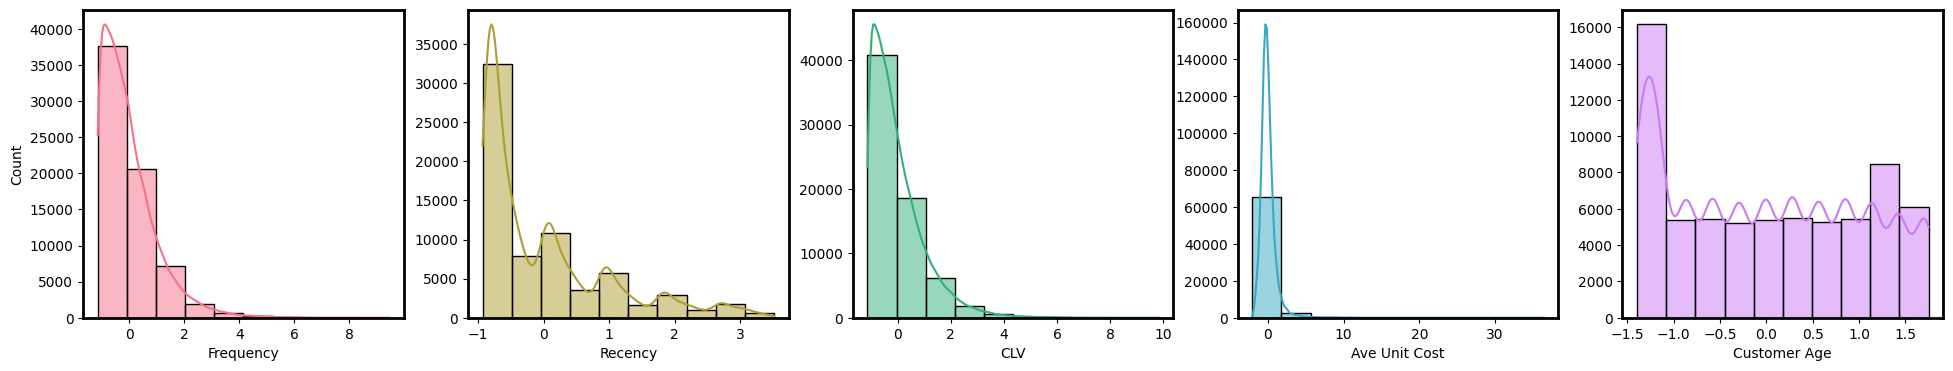

In [ ]:
# Create histograms to visualise distribution

fig, axes = plt.subplots(1, 5, figsize=(24, 4))
palette1 = iter(sns.husl_palette(5))
cols=df_scaled.columns.to_list()
for i,col in enumerate(cols):
  sns.histplot(df_scaled[col], ax=axes[i], color=next(palette1),bins=10,kde=True)

  for axs in ['top','bottom','left','right']:
    axes[i].spines[axs].set_linewidth(2)

plt.setp(axes, ylabel="")
axes[0].set_ylabel('Count')
#plt.savefig("Histograms_2.svg")
plt.show()


It can be seen that none of the features visualised follow a normal distribution as all the histograms produced are right-skewed. In the case of 'Customer Age', what would be a nearly uniform distribution is violated by a high percentage of customers who are below the age of 35, as well as those aged between 70-80. A log-scale transformation may be applied to eliminate skewness which would make more sense in the context of price, i.e. for features such as 'CLV' or 'Ave Unit Cost'. However, the largest data ranges belong to 'CLV' and 'Recency'. Thus, without domain knowledge taking the log of certain features runs the risk of loss of interpretation.

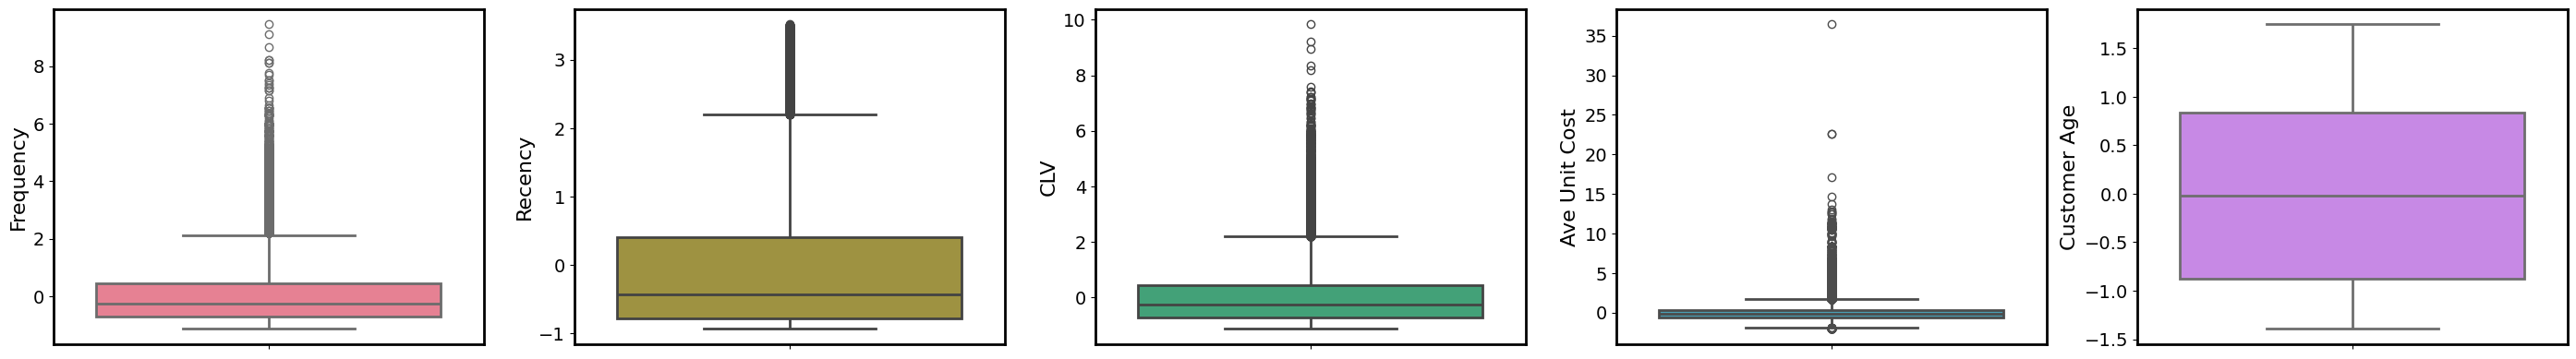

In [ ]:
# Create box plots to visualise outliers
fig, axes = plt.subplots(1, 5, figsize=(28, 4))
palette1 = iter(sns.husl_palette(5))
for i,col in enumerate(cols):
 sns.boxplot(y=df_scaled[col], ax=axes[i],color=next(palette1),linewidth=2)
 axes[i].set_ylabel(col,fontsize=16)
 axes[i].tick_params(axis='both', which='major', labelsize=14)

 for axs in ['top','bottom','left','right']:
      axes[i].spines[axs].set_linewidth(2)

plt.tight_layout()
#plt.savefig("boxplots_2.svg")
plt.show()

With the exception of Customer Age, the box plots indicate a significant presence of outliers which are pre-dominantly found beyond the maximum (upper whisker). This is to be expected given the asymmetric distribution of data across the created features. These data points could simply be naturally occurring extremes as opposed to anomalous cases or errors.

### 3.2 Outliers

A simple statistical analysis incorparing the IQR can be performed to determine the percentage of outliers per feature which will be defined as the datapoints that fall outside the maximum and minimum of the boxplots (the upper and lower whiskers).

In [ ]:
# Sort values in ascending order
sorted =df_scaled.apply(lambda x: x.sort_values().values)

# The IQR approach
for col in sorted.columns.tolist():

  # Calculate the quantiles
  q1 = sorted[col].quantile(0.25)
  q3 = sorted[col].quantile(0.75)


  # Compute the IQR.
  iqr = q3 - q1

  # Calculate the upper and lower limits
  lower = q1-1.5*iqr
  upper = q3+1.5*iqr

  outlier_count=((sorted[col] < lower) | (sorted[col] > upper)).sum()

  percentage= round(outlier_count.sum() /len(df_scaled)*100,2)
  print(col + ':', outlier_count,'(',percentage,'%)')


Frequency: 2654 ( 3.89 %)
Recency: 3353 ( 4.91 %)
CLV: 2590 ( 3.79 %)
Ave Unit Cost: 2889 ( 4.23 %)
Customer Age: 0 ( 0.0 %)


The combined percentage of outliers is 16.82% which may be considered high. However, there is no information regarding what constitutes an outlier within the context of an e-commerce dataset containing customer- and purchase-related data. Thus, without knowing the contamination rate, the treatment of outliers necessisates domain knowledge.

In [ ]:
# Function to remove outliers
# from sklearn.ensemble import IsolationForest

# def remove_outliers(X):

#     # the Isolation Forest model
#     iso_forest = IsolationForest(contamination=0.1, random_state=42)

#     # fit and predict the outliers
#     y = iso_forest.fit_predict(X)


#     # keep only the rows flagged 1 which indicates inliers
#     mask = y == 1

#     print(f"Rows removed as outliers: {(~mask).sum()}")

#     # return both X and y filtered with the same mask
#     return X[mask], y[mask]

## 4.Determining the Optimum Number of Clusters

### 4.1 Using the Elbow Method

In [ ]:
# Elbow Method
wcss=[]
# try different k within the range of 2-15 clusters.
for i in range(2,16):
# the k-means++ method spreads the initial centroids as far apart as possible.
    kmeans=KMeans(n_clusters=i, init='k-means++',random_state=0, n_init = 10)
    kmeans.fit(df_scaled)
# calculate the inertia or the loss, for each k value.
    wcss.append(kmeans.inertia_)


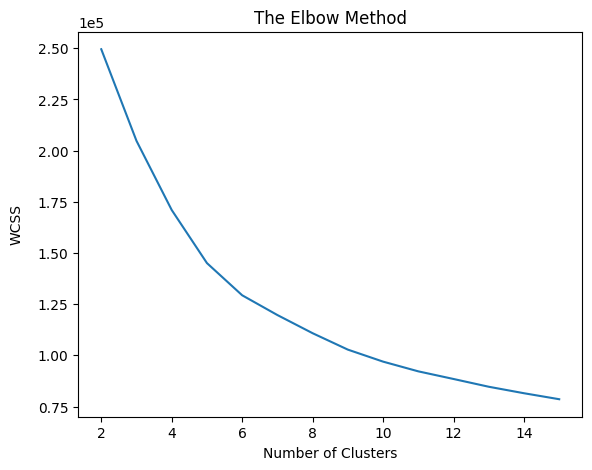

In [ ]:
plt.figure(figsize=(6.5,5))
plt.plot(range(2,16),wcss)
plt.title('The Elbow Method')
plt.xlabel('Number of Clusters')
plt.ylabel('WCSS',labelpad=10)
plt.ticklabel_format(axis='y', style='sci', scilimits=(4,5))

plt.savefig("elbow.png")
plt.show()

The Within-Cluster Sum of Squares (WCSS) is expected to decrease as an increased number of clusters (higher k) will reduce the within-cluster spread until a point of diminishing returns is reached. Thus, the elbow plot shows the variation in WCSS with increasing number of clusters. In the current case, the resulting elbow plot is highly subjective since the first point of plateau (inertia) can be taken as any value between 6 and 8 clusters.

### 4.2 Based on the Silhoutte Scores

In [ ]:
# The Silhoutte Scores Method
silhouette_scores = []
for kn in range(2,11):
    # Initialize the clusterer with n_clusters value and a random generator
    # seed of 10 for reproducibility.
    clusterer = KMeans(n_clusters=kn, random_state=10, n_init = 10)
    cluster_labels = clusterer.fit_predict(df_scaled)

    # The silhouette_score gives the average value for all the samples.
    # This gives a perspective into the density and separation of the formed
    # clusters.
    silhouette_avg = silhouette_score(df_scaled, cluster_labels)
    print("For n_clusters =", kn,
          "The average silhouette_score is :", silhouette_avg)
    silhouette_scores.append(silhouette_avg)

For n_clusters = 2 The average silhouette_score is : 0.26119917429929
For n_clusters = 3 The average silhouette_score is : 0.2526075519647803
For n_clusters = 4 The average silhouette_score is : 0.25319982728412876
For n_clusters = 5 The average silhouette_score is : 0.2669682545598477
For n_clusters = 6 The average silhouette_score is : 0.2523164371383424
For n_clusters = 7 The average silhouette_score is : 0.23430914549715232
For n_clusters = 8 The average silhouette_score is : 0.23548392626213427
For n_clusters = 9 The average silhouette_score is : 0.2402635194003328
For n_clusters = 10 The average silhouette_score is : 0.2251960297422894


While the elbow method is mainly indicative of the intra-cluster spread, the silhouette score incorporates both the intra- and nearest (inter)-cluster spread, thereby informing of the quality of the clusters formed. For the current dataset, the average silhouette score is around 0.25 which is on the low side and therefore, indicative of potential cluster overlaps. Most notably, the highest silhouette score is obtained for the case of 5 clusters.

In [ ]:
print(silhouette_scores[4]/max(silhouette_scores))
print(silhouette_scores[2]/max(silhouette_scores))
print(silhouette_scores[1]/max(silhouette_scores))

0.9451177539978982
0.9484267247489069
0.9462082013505914


In [ ]:
print(np.array(silhouette_scores).mean())

0.24683820734981088


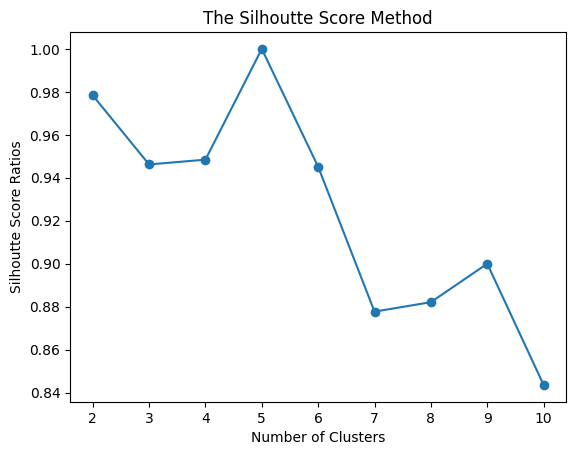

In [ ]:
# Plot and Compare results to WCSS approach
plt.plot(range(2,11),silhouette_scores/max(silhouette_scores),marker='o')
plt.xlabel('Number of Clusters')
plt.ylabel('Silhoutte Score Ratios')
plt.title('The Silhoutte Score Method')
plt.savefig("silhouette.png")
plt.show()


When we plot the silhouette score ratios to that of the maximum silhouette score (obtained when k=5), we see that the silhouette scores obtained for k=3, 4 and 6 are nearly 95% of the silhouette score obtained for k=5. Indeed a case of k=6 is more consistent with the picture painted by the elbow plot.

### 4.3 Perform hierarchical clustering and create a dendogram to identify/confirm potential number of clusters (k).

In [ ]:
# Here sample a subset of rows to stop the colab notebook from crashing
df_sample = df_scaled.sample(n=30000,random_state=10).reset_index(drop = True)

For the hierarchical clustering the 'ward' linkage method is chosen since the distance between the clusters is taken to be the distance between the two centroids which is akin to the k-means clustering approach.

In [ ]:
# Hierarchical Clustering
def hierarchical_clustering(data, method='ward'):
    # compute pairwise distances between data points
    dists = pdist(data, metric='euclidean')
    linkage_matrix = linkage(dists, method=method)
    return linkage_matrix


In [ ]:
# Compute the linkage matrix
linkage_matrix = hierarchical_clustering(df_sample)

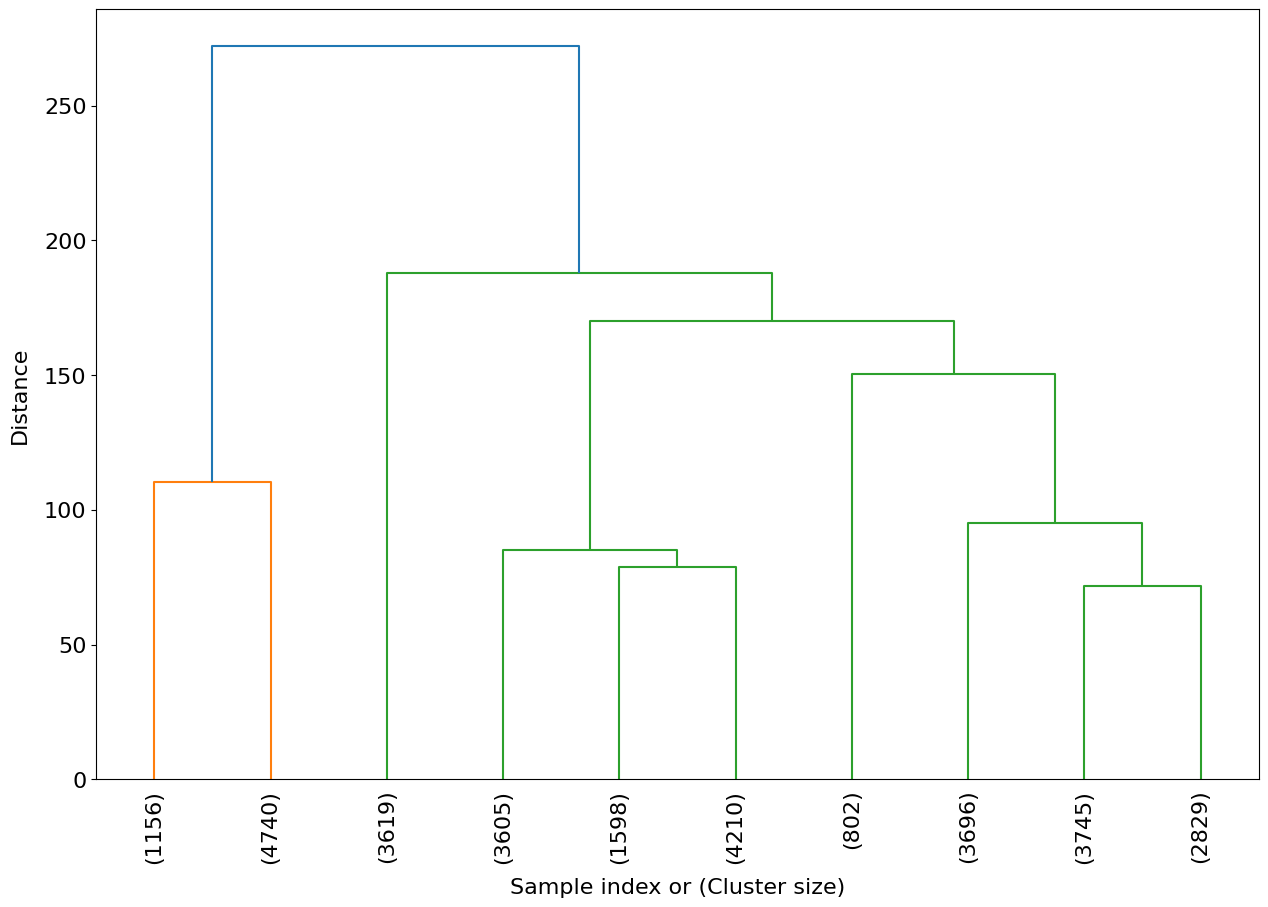

In [ ]:
# Plot the dendrogram
plt.figure(figsize=(15, 10))
# Here p=10 prunes the dendogram to the 10 top-most populated clusters
dendrogram(linkage_matrix, truncate_mode='lastp', p=10, leaf_rotation=90, leaf_font_size=16)
#plt.title('Dendrogram',y=1.03)
plt.yticks(fontsize=16)
plt.xlabel('Sample index or (Cluster size)',fontsize=16,labelpad=10)
plt.ylabel('Distance',fontsize=16,labelpad=10)
plt.savefig("Dendrogram.svg")
plt.show()

* At a distance of 110, 5 clusters will have formed with a reasonable horizontal separation between the different groups.

* When the cut-off distance is lowerd to 100, 6 clusters will have formed. Clearly, the jump from 6 clusters to the next merge leading to 5 clusters is a relatively short distance.

* Upon further lowering the threshold distance, 7 to 10 clusters will be present over a range between 70-90 which obscures the picture.

* Moving in the opposite direction, when the horizontal cut-off is increased just above 150 and then above 170, the consecutive merges yield 4 and 3 clusters respectively.

* When the close jump between these two merges is taken into account, the longest distance range is achieved for the case of *k*=5. However, the possibility of *k*=3 or 4 cannot be eliminated.

* A case of k=5 is also the most agreeable with the computed silhouette scores while not being too far from the range of decline suggested by the elbow plot.


## 5.K-means Clustering

### 5.1 Based on the optimum number of k, perform k-means clustering.

In [ ]:
# Using our best "k" and plotting the results.
def perform_kmeans(data,k):
  clusterer = KMeans(n_clusters = k,
                   random_state=10,
                   n_init = 10)

  cluster_labels = clusterer.fit_predict(df_scaled)
  return cluster_labels


In [ ]:
cluster_labels=perform_kmeans(df_scaled,5)


### 5.2 View the cluster number associated with each Customer ID.

In [ ]:
# Let's create a new data frame to store cluster labels alongside customer ID
df_cluster=df_scaled.copy()
df_cluster['Customer ID']=df_agg.index
df_cluster['Cluster']=cluster_labels


display(df_cluster.head(10))

,Frequency,Recency,CLV,Ave Unit Cost,Customer Age,Customer ID,Cluster
0,1.859578,-0.843377,1.379468,0.282257,1.120231,1,1
1,0.535510,-0.597171,0.506337,0.305469,-0.594773,3,4
2,-0.435473,1.790064,-0.678804,-1.097228,-0.594773,4,3
3,0.447239,-0.872342,0.500511,0.764418,-0.880607,5,4
4,0.094154,-0.425792,-0.200923,-0.693830,0.834397,6,2
5,1.506493,-0.582688,0.239869,-0.877530,-0.880607,7,4
6,0.712053,-0.599584,1.653669,0.621444,-0.537607,9,1
7,1.594765,-0.840963,1.547262,0.055288,-1.166441,10,1
8,-0.435473,-0.799929,-0.843163,-1.063782,-0.594773,11,4
9,0.182425,-0.633377,-0.136722,-0.686145,-0.251773,12,4


### 5.3 Boxplots to display the clusters with regard to frequency, recency, CLV, average unit cost, and customer age.

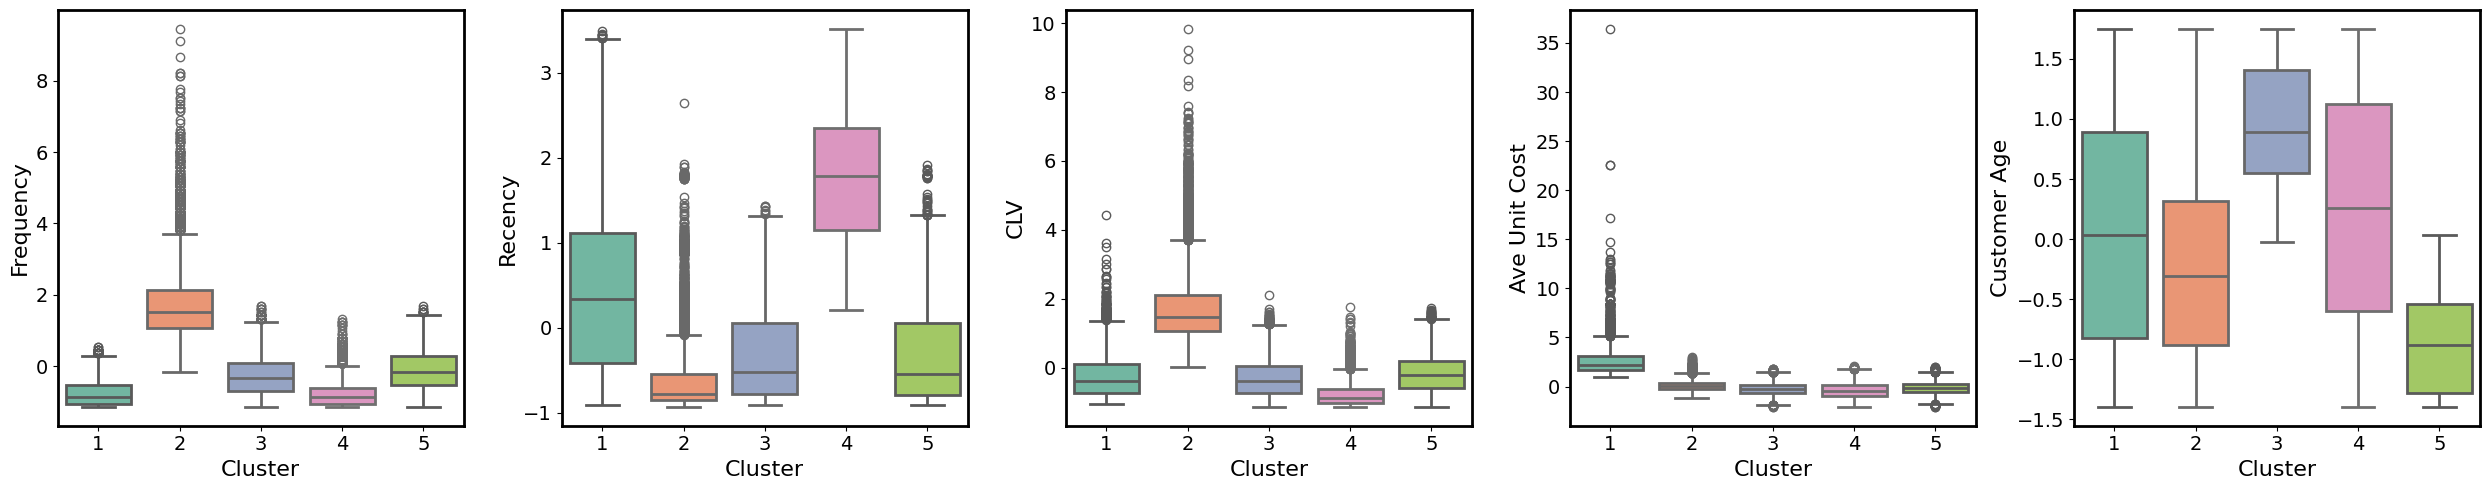

In [ ]:
# Create the boxplots

n_features=5
n_clusters=len(df_cluster['Cluster'].unique())
cols=df_scaled.columns.to_list()
colors2 = mpl.colormaps['Set2'].colors


fig, axes = plt.subplots(1, n_features, figsize=(25, 5))

for i in range(n_features):
  for cluster_idx in range(n_clusters):
    cluster_data=df_cluster[df_cluster['Cluster'] == cluster_idx]
    sns.boxplot(x=cluster_data['Cluster']+1,y=cluster_data[cols[i]], ax=axes[i],color=colors2[cluster_idx],linewidth=2)
  axes[i].set_xlabel('Cluster',fontsize=16)
  axes[i].set_ylabel(cols[i],fontsize=16)
  axes[i].tick_params(axis='both', which='major', labelsize=14)

  for axs in ['top','bottom','left','right']:
      axes[i].spines[axs].set_linewidth(2)

plt.tight_layout()
#plt.savefig("clustered_boxplots.svg")
plt.show()


* Frequency: Potential overlaps between clusters 1 and 4 as well as clusters 3 and 5 as the datapoints are concentrated at the bottom quarter of the full scale.

* Recency: Potential overlaps between clusters 2, 3 and 5.

* CLV: Once again the data is squeezed into the bottom quarter of the full scale where overlaps amongst clusters 1, 3, 4 and 5 are likely.

* Ave Unit Cost: Likewise, expect overlaps between all clusters apart from the 1st cluster which stands out due to the asymmetric distribution of datapoints.

* Customer age: While the box plots are more spread for this feature, clusters 1, 2, 3 and 4 are likely to overlap.

## 6.Dimension Reduction for 2D Visualisation

### 6.1 Perform dimension reduction with two component PCA

In [ ]:
# Apply PCA.
pca = PCA(n_components=2)
X_pca = pca.fit_transform(df_scaled)

In [ ]:
# Merge the principal components with the k-means cluster labels.
columns = ['PC1','PC2']
df_pca  = pd.DataFrame(X_pca, columns=columns, index=[''] * len(X_pca))

df_pca['Cluster']=cluster_labels


print(df_pca)

         PC1       PC2  Cluster
    2.186174  0.062282        1
    1.040686  0.171029        4
   -1.428117 -0.699789        3
    1.190183  0.559836        4
   -0.101799 -0.799061        2
..       ...       ...      ...
   -1.039558  0.571447        3
   -1.138862  1.226892        3
    4.927447  0.030645        1
   -0.554325 -0.117004        2
   -1.344066  0.602737        3

[68300 rows x 3 columns]


### 6.2 Create a 2D visualisation using the PCA output to display the clusters with different colours.

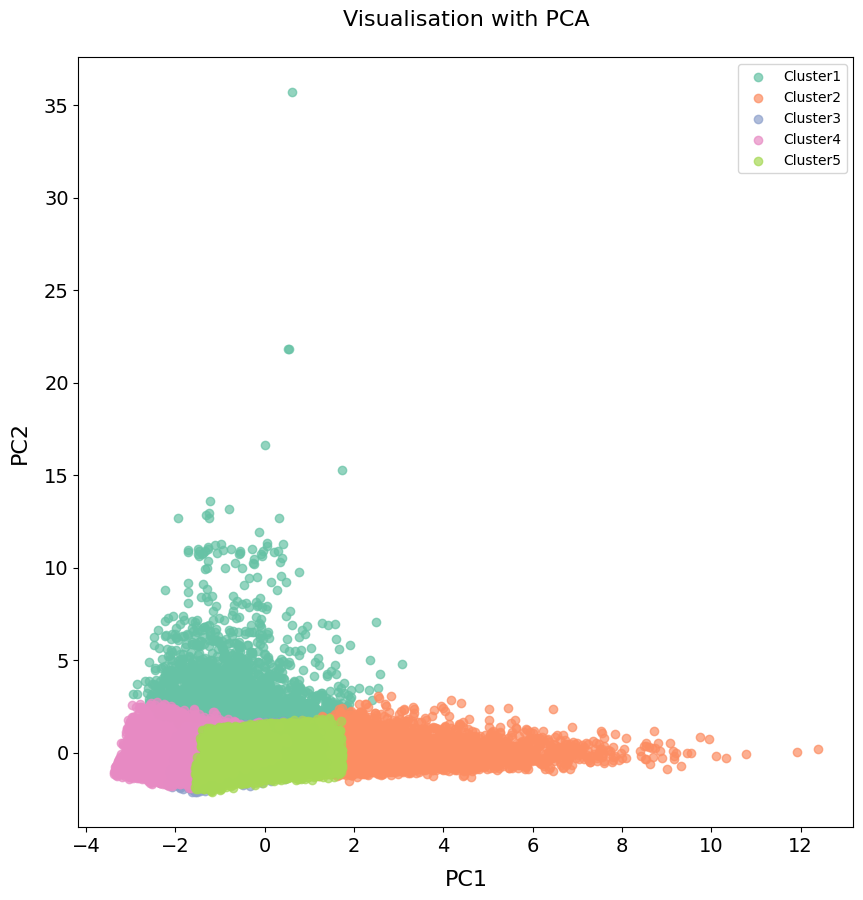

In [ ]:
# Visualise the reduced data in 2D.
colors2 = mpl.colormaps['Set2'].colors
n_clusters=5

plt.figure(figsize=(10, 10))

for cluster_idx in range(n_clusters):
    cluster_data=df_pca[df_pca['Cluster'] == cluster_idx]
    plt.scatter(cluster_data['PC1'],
              cluster_data['PC2'],
              color=colors2[cluster_idx],alpha=0.7,label='Cluster'+ str(cluster_idx+1))
plt.tick_params(axis='both', which='major', labelsize=14)

for axs in ['top','bottom','left','right']:
    axes[i].spines[axs].set_linewidth(2)
plt.legend()
plt.xlabel('PC1',fontsize=16,labelpad=10)
plt.ylabel('PC2',fontsize=16,labelpad=10)
plt.title('Visualisation with PCA',y=1.03,fontsize=16)
#plt.savefig('PCA_k5.svg')
#plt.savefig('PCA_k5.png')
plt.show()


The PCA plot indicates the clustering has been very soft with significant overlaps between all the clusters. Indeed, cluster 3 is barely visible and appears contained by other groups. This could be due to a poor choice of *k*, however, it is important to recall that PCA projects the data along the axes that present with the most variance. Thus, there could be a loss of structure moving from real space to the principal axes.

In [ ]:
# Create a DataFrame to store explained variance:
df_variance = pd.DataFrame({
    'PC': range(1, len(pca.explained_variance_ratio_) + 1),
    'Explained Variance': pca.explained_variance_ratio_
})

# Print the DataFrame.
print(df_variance.to_string(index=False))
print('Cumulative Sum:', df_variance['Explained Variance'].sum())

 PC  Explained Variance
  1            0.445275
  2            0.207263
Cumulative Sum: 0.6525375282308347


When the explained variance is computed for the two components used in the 2D visualisation, it is found that PC1 and PC2 explain 65.25% of the variance present within the multivariate dataset. This signals a considerable loss of interpretability.

### 6.3 Perform dimension reduction with t-SNE

In [ ]:
# A perplexity value is chosen such that the 2D visualisation produced reflects a meaningful general-pattern
tsne = TSNE(n_components = 2, perplexity = 20, random_state=10)
tsne_results = tsne.fit_transform(df_scaled)



In [ ]:
# Merge the t-SNE components with the k-means cluster labels.
columns = ['Component1','Component2']
df_tsne  = pd.DataFrame(tsne_results, columns=columns, index=[''] * len(tsne_results))

df_tsne['Cluster']=cluster_labels

display(df_tsne)

,Component1,Component2,Cluster
,50.267982,80.485031,1
,57.608387,-2.390737,4
,-62.691795,80.118805,3
,67.700256,-11.276642,4
,-25.773815,-13.241681,2
...,...,...,...
,-32.970211,61.627880,3
,-14.363890,94.588326,3
,81.659050,67.807198,1
,-15.057821,-44.244827,2


### 6.4 Create a 2D visualisation using the t-SNE output to display the clusters with different colours.

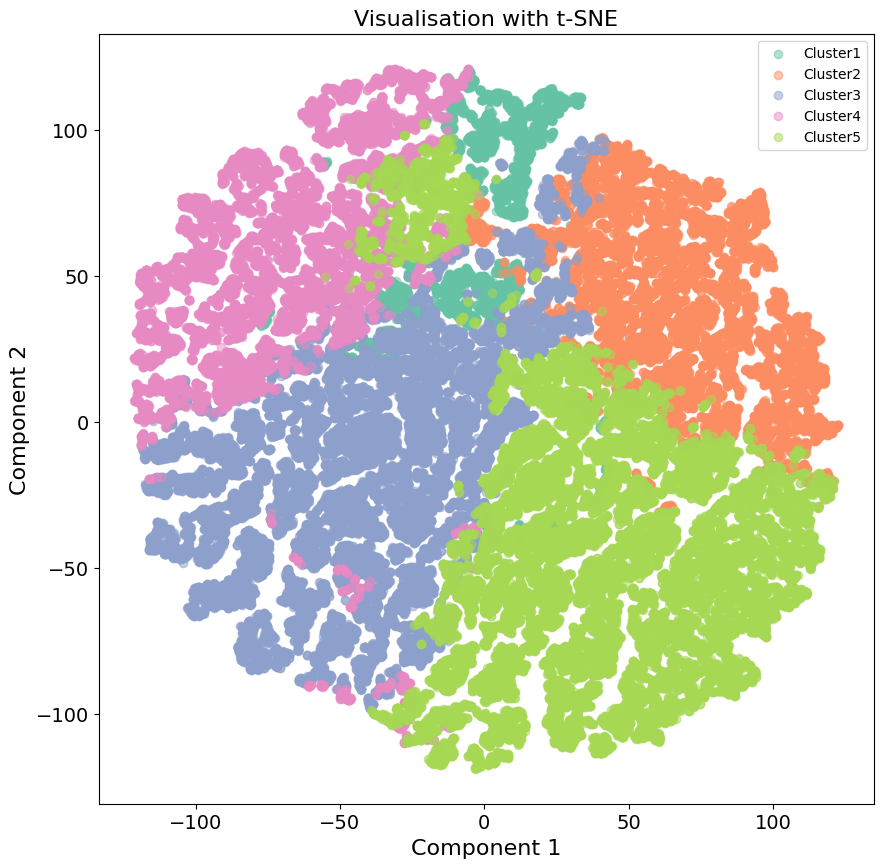

In [ ]:
# Visualise the reduced data in 2D.
n_clusters=5
colors2 = mpl.colormaps['Set2'].colors
plt.figure(figsize=(10, 10))
for cluster_idx in range(n_clusters):
    cluster_data=df_tsne[df_tsne['Cluster'] == cluster_idx]
    plt.scatter(cluster_data['Component1'],
                cluster_data['Component2'],
                color=colors2[cluster_idx],alpha=0.5,
                label='Cluster'+ str(cluster_idx+1))
plt.xlabel('Component 1',fontsize=16)
plt.ylabel('Component 2',fontsize=16)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
for axs in ['top','bottom','left','right']:
    axes[i].spines[axs].set_linewidth(2)
plt.legend()
plt.title('Visualisation with t-SNE',y=1.0,fontsize=16)
#plt.savefig('tSNE_k5.svg')
#plt.savefig('tSNE_k5.png')
plt.show()

Visualisation with t-SNE produces a significantly clearer picture where the 5 clusters become better separated or resolved. However, the overlaps are not eliminated, which is especially true for the region where cluster 1 is formed. Further mixing also occurs at the bottom-left corner where clusters 3 and 4 overlap. Considering the relatively smaller size of cluster 1, reducing *k* to 4 may be useful as this would reduce mixing and produce better defined borders.

## 7.Further Analysis

### 7.1 Compute mutual information (MI) scores to see the dependence of cluster labelling on the 5 features created.

In [ ]:
# Employ mutual information (MI) to measure dependency between features
from sklearn.feature_selection import mutual_info_regression

def calculate_mi(df, y):
 # Calculate MI for all features.
 mi_scores = mutual_info_regression(df, y, random_state=42)
 mi_df = pd.DataFrame({'Feature': df.columns, 'MI Score': mi_scores})

 # Sort features by MI score in descending order.
 mi_df = mi_df.sort_values(by='MI Score', ascending=False).reset_index(drop=True)

 return mi_df

In [ ]:
# As cluster labels are the outcome, it can be taken as the target variable
mi_df = calculate_mi(df_scaled,cluster_labels)
print(mi_df)

         Feature  MI Score
0      Frequency  0.455962
1            CLV  0.448867
2   Customer Age  0.430940
3        Recency  0.381293
4  Ave Unit Cost  0.257765


* The MI scores computed give an indication of the weight with which each of the five features are contributing to the grouping of the dataset into 5 clusters.

* The higher the MI score, the higher the dependency between that feature and the targert variable which in this case is the cluster label.

* Thus, the top three features -'Frequency', 'CLV' and 'Customer Age'- are better determinants for the segmentation of the customer base with 'Recency' coming in at a close 4th.

* The 'Ave(rage) Unit Cost' which indicates customer preference for low- or high-cost items seems to have a lesser yet non-negligible effect.

* However, the approach is only a tool in interpreting the effectiveness of the feature selection ( in the current scenario of 5 distinct customer groups) and does not give direct information on the effectiveness of the clustering itself. Thus, it is important to focus on the results returned by PCA and t-SNE following dimenionality reduction.

### 7.2 Repeat PCA analysis for k=3 and 4 and compare results to the case of k=5.

In [ ]:
# Perform K-means with 3, 4 and 5 clusters
cluster_labels_3=perform_kmeans(df_scaled,3)
cluster_labels_5=perform_kmeans(df_scaled,5)
cluster_labels_4=perform_kmeans(df_scaled,4)

In [ ]:
# Merge the principal components with the new cluster labels.
columns = ['PC1','PC2']
df_pca_new  = pd.DataFrame(X_pca, columns=columns, index=[''] * len(X_pca))

df_pca_new['Cluster3']=cluster_labels_3
df_pca_new['Cluster5']=cluster_labels_5
df_pca_new['Cluster4']=cluster_labels_4

print(df_pca_new)

         PC1       PC2  Cluster3  Cluster5  Cluster4
    2.186174  0.062282         2         1         3
    1.040686  0.171029         0         4         0
   -1.428117 -0.699789         1         3         2
    1.190183  0.559836         0         4         0
   -0.101799 -0.799061         0         2         1
..       ...       ...       ...       ...       ...
   -1.039558  0.571447         1         3         2
   -1.138862  1.226892         1         3         2
    4.927447  0.030645         2         1         3
   -0.554325 -0.117004         0         2         1
   -1.344066  0.602737         1         3         2

[68300 rows x 5 columns]


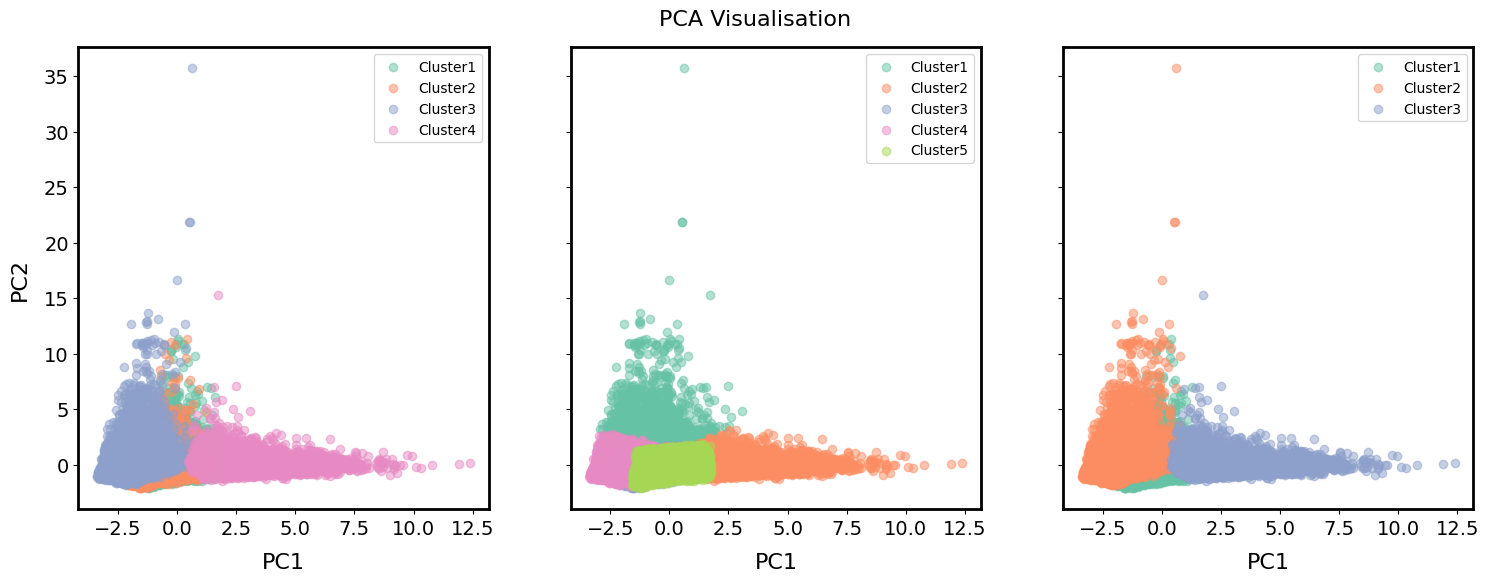

In [ ]:
# Visualise in 2D:
colors2 = mpl.colormaps['Set2'].colors
n_clusters=[4,5,3]
cols=['Cluster4','Cluster5','Cluster3']
fig, axes = plt.subplots(1, 3, figsize=(18, 6),sharey=True)
for i in range(len(n_clusters)):
  for cluster_idx in range(n_clusters[i]):
      cluster_data=df_pca_new[df_pca_new[cols[i]] == cluster_idx]
      axes[i].scatter(cluster_data['PC1'],
                cluster_data['PC2'],
                color=colors2[cluster_idx],alpha=0.5,label='Cluster'+ str(cluster_idx+1))
  axes[i].tick_params(axis='both', which='major', labelsize=14)
  axes[i].legend()
  axes[i].set_xlabel('PC1',fontsize=16,labelpad=10)

  for axs in ['top','bottom','left','right']:
      axes[i].spines[axs].set_linewidth(2)
axes[0].set_ylabel('PC2',fontsize=16,labelpad=10)
plt.title('PCA Visualisation',x=-0.75,y=1.03,fontsize=16)
#plt.savefig('PCA_k543.svg')
#plt.savefig('PCA_k543.png')
plt.show()


The PCA outputs obtained for lower *k* values indicate the clustering remains soft with the inter-cluster overlaps persisting. However, compared to the case of *k*=5, the cluster borders are better defined.

### 7.3 Repeat t-SNE analysis for k=3 and 4 and compare results to the case of k=5.

In [ ]:
# Merge the t-SNE components with the new k-means clusters labels.
columns = ['Component1','Component2']
df_tsne_new  = pd.DataFrame(tsne_results, columns=columns, index=[''] * len(tsne_results))

df_tsne_new['Cluster3']=cluster_labels_3
df_tsne_new['Cluster4']=cluster_labels_4
df_tsne_new['Cluster5']=cluster_labels_5

display(df_tsne_new)

,Component1,Component2,Cluster3,Cluster4,Cluster5
,50.267982,80.485031,2,3,1
,57.608387,-2.390737,0,0,4
,-62.691795,80.118805,1,2,3
,67.700256,-11.276642,0,0,4
,-25.773815,-13.241681,0,1,2
...,...,...,...,...,...
,-32.970211,61.627880,1,2,3
,-14.363890,94.588326,1,2,3
,81.659050,67.807198,2,3,1
,-15.057821,-44.244827,0,1,2


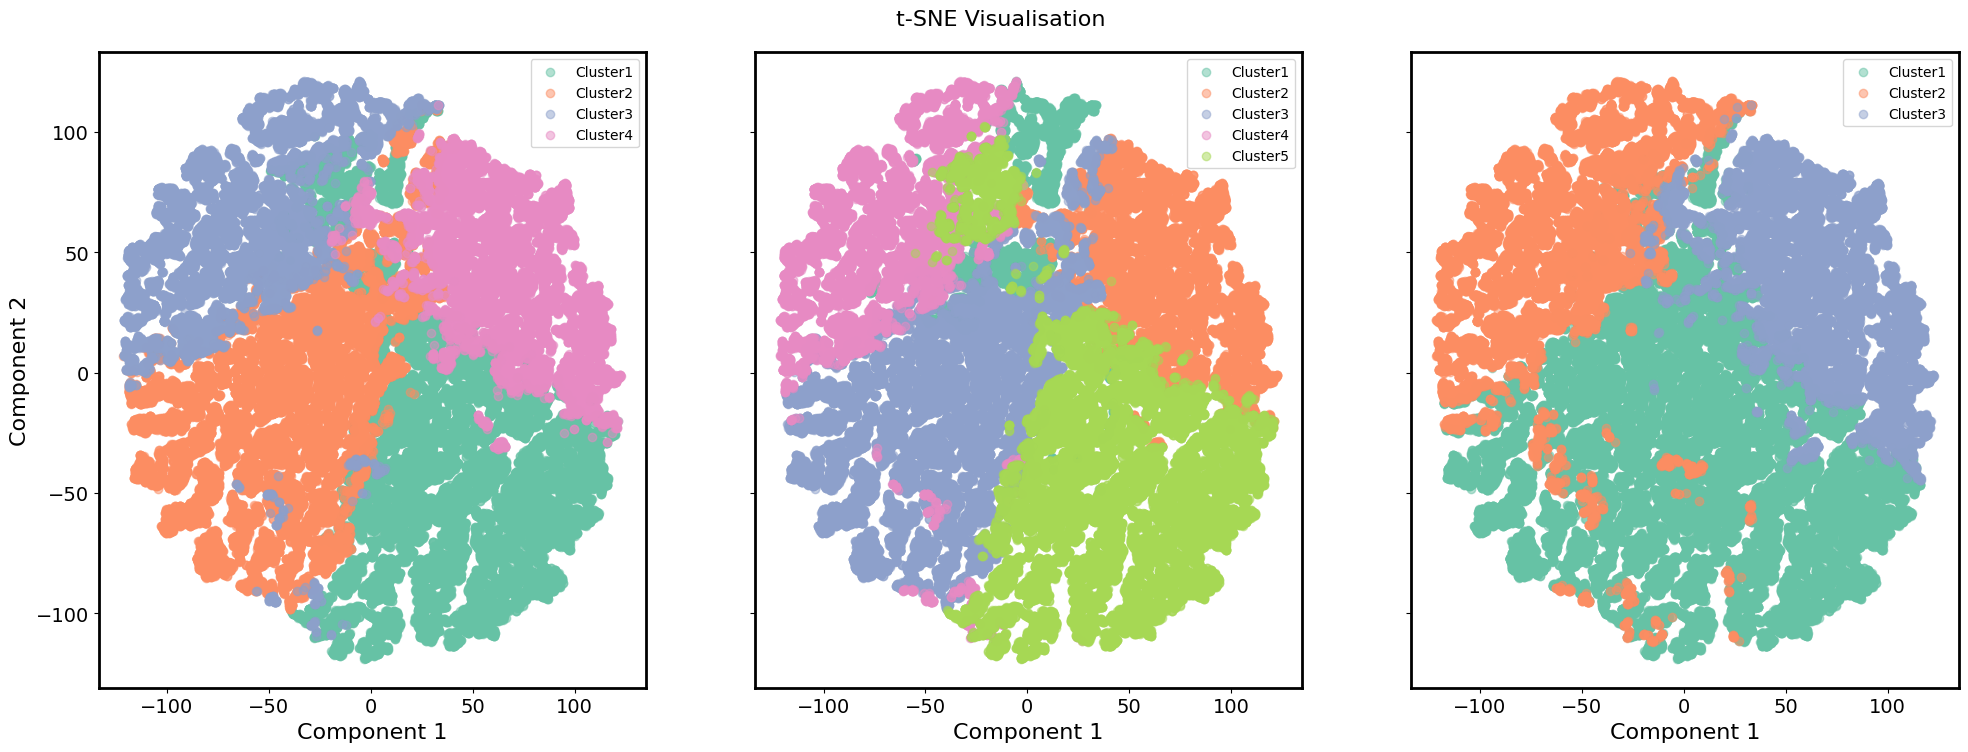

In [ ]:
# Visualise in 2D:
colors2 = mpl.colormaps['Set2'].colors
n_clusters=[4,5,3]
cols=['Cluster4','Cluster5','Cluster3']
fig, axes = plt.subplots(1, 3, figsize=(24, 8.25),sharey=True)
for i in range(len(n_clusters)):
  for cluster_idx in range(n_clusters[i]):
      cluster_data=df_tsne_new[df_tsne_new[cols[i]] == cluster_idx]
      axes[i].scatter(cluster_data['Component1'],
                cluster_data['Component2'],
                color=colors2[cluster_idx],alpha=0.5,label='Cluster'+ str(cluster_idx+1))
  axes[i].tick_params(axis='both', which='major', labelsize=14)
  axes[i].legend()
  axes[i].set_xlabel('Component 1',fontsize=16)

  for axs in ['top','bottom','left','right']:
      axes[i].spines[axs].set_linewidth(2)
axes[0].set_ylabel('Component 2',fontsize=16)
plt.title('t-SNE Visualisation',x=-0.75,y=1.03,fontsize=16)
#plt.savefig('tSNE_k543.svg')
#plt.savefig('tSNE_k543.png')
plt.show()


The t-SNE output for the cases of *k*=3 and 4 produce a clearer pattern between the resulting groups and the mixing is slightly reduced compared to the *k*=5 case. Amongst all the cases tested, *k*=4 appears to be the optimal scenario where the borders are better-defined without loss of nuance as in the case of *k*=3.

## 8.Summary & Conclusions:

An e-commerce dataset comprising 951,668 rows and 20 features has been analysed with the objective of performing customer segmentation using the optimal number of clusters, *k*.

The dataset was pre-processed for missing values and duplicates (sections 1.3-1.4) following which feature creation (section 2.1) was performed based on a marketing perspective. As a result, 5 new features including *frequency*, *recency*, *CLV*, *average unit cost*, and *customer age* was created to capture nuances in customer purchasing behaviours. The new features were aggregated in a row-wise fashion based on the unique customer ID (section 2.2).

Next, feature scaling was performed using a standard scaler to obtain a comparable range for all the features (section 2.3). EDA (section 3) was performed on the resulting dataset, where the histogram plots indicated none of the new features followed a normal distribution, and the boxplots suggested a significant percentage of outliers.

A quick IQR analysis (section 3.2) was performed to determine the total percentage of potential outliers which was found to be 16.82%. As what is considered outliers in this scenario could constitute naturally occurring extremes within the customer base, further domain knowledge would be needed to treat them.

Following the data pre-processing, the optimal number of clusters with which to perform k-means was determined first using two statistical approaches: The elbow method (section 4.1) and the silhouette scores approach (section 4.2). The elbow method produced a highly objective plot where the point of inertia could be placed at any point between *k*=6 and 8 with the most-likely scenario being *k*=6. The silhouette scores computed on the other hand returned a maximum for *k*=5 which was closely followed by *k*=3,4 and 6.

Most notably, the average silhouette score obtained was ~ 0.25 which indicated the inter-cluster distance was not that much greater than the intra-cluster distance, signalling potential overlaps. Amongst the two approaches, the silhouette score may be considered more informative about the cluster quality as it incorporates both the nearest-neighbour and the within-cluster distances.

Next, (agglomerative) hierarchical clustering (section 4.3) was performed on a subset of 30,000 datapoints and at a depth of 10 clusters. A manual interpretation of the resulting hierarchical suggested a case of *k*=5 would be optimal, consistent with the silhouette scores. However, possibility of *k*=3 or 4 could not be eliminated.

Thus, based on the 3 approaches k-means clustering was performed with *k*=3 (section 5) and the results were visualised using boxplots obtained per feature (section 5.3). The distribution of the resulting 5 clusters making up the 5 colour-coded boxes in the boxplots indicated potential overlaps.

Dimensionality reduction was performed using both PCA and t-SNE (section 6), to permit visualisation in 2D. The PCA output showed the cluster borders were not defined well, with significant overlaps amongst the clusters. As the two principal components could only account for 65.25% of the variation present within the dataset, a considerable loss of interpretation was also evident. That said, datapoints that appeared as outliers were assigned in a way that reflected the clustered boxplots.

The t-SNE output presented with a significantly clearer pattern, albeit this came at a significant computational cost. The t-SNE data while still indicative of a case of soft clustering with overlaps, showed some pattern of spread amongst the 5 groups. Most strikingly, cluster 1 appeared  comparatively small which contributed to further mixing. This prompted the idea that a case of *k=* 4 or even *k=*3 should be re-evaluated.

Thus, further analysis was carried out through additional PCA and t-SNE plots obtained with *k=* 3 and 4 which was then compared to the case of *k*=5. Based on PCA visualisations, the difference in interpretability between *k*=3 and 4 was not significant as both cases presented with intersecting clusters. However, the t-SNE outputs suggested the optimal scenario for customer segmentation would be obtained using *k*=4, since the nuances amongst the different customer cohorts were preserved while the cluster resolution was improved with better defined borders emerging.

The two dimensionality reduction approaches proved powerful in determining the optimal number of clusters by offering 2D visualisations. This was especially true for t-SNE, which improved separability of the data and made the cluster motifs discernible. Moreover, the case of *k*=4 still agrees with the silhouette score assessment as well as the dendrogram interpretation, except the final merge distinguishing a case of 4 clusters from 3 happens over a relatively short distance.













## References:
SAS, 2024. CUSTOMERS_CLEAN [Data set]. SAS. Last revised on 15 December 2021. [Accessed 20 February 2024].